## Evaluating a collected day against a GOLD day

This notebook compares two JSON descriptions of a day in somebody's life:

* the **key**: the GOLD description, e.g. one of the example days in ```data/example_days```
* the **collected** description: the day collected by an agent, e.g. by the ```DayInterviewer``` in ```src/cltl/demo_chatbot```, saved in ```data/collected_days```

Both files have the same structure: ```event1```, ```event2```, ... with the roles ```who```, ```what```, ```with_what```, ```with_whom```, ```where```, ```when``` and ```how_long``` and the ```coreference_chains``` of the people in the events.

First we show the basic statistics of both days with ```day_statistics.py```, then we evaluate the collected day against the key with ```day_evaluation.py```.

In [1]:
import sys
from pathlib import Path

# Jupyter runs the notebook in its own folder. We add the root of the project to the path,
# so that the modules can be imported from src.cltl
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "src" / "cltl").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import json
import pandas as pd
from IPython.display import display
from src.cltl.demo_chatbot.day_statistics import save_day_statistics, get_events
from src.cltl.task_evaluation.day_evaluation import evaluate_files, save_turn_evaluation, read_turn_effectiveness,EVENT_THRESHOLD

## The two days

Set ```KEY``` to the GOLD day and ```COLLECTED``` to the day collected by the agent. By default, the collected day is the most recent day in ```data/collected_days```. The evaluation is most meaningful when the collected day describes the same day as the key, e.g. when you told the agent about the day of Emma in ```day1_emma_student.json```.

```EVENT_THRESHOLD``` is the minimal similarity to align a collected event with a GOLD event, from the time, the event type and the label of the events (see ```day_evaluation.py```).

In [3]:
KEY = PROJECT_ROOT / "data" / "example_days" / "day1_emma_student.json"

# the most recent collected day, skipping the files with statistics and evaluations
collected_days = [path for path in (PROJECT_ROOT / "data" / "collected_days").glob("*.json")
                  if not path.stem.endswith(("_meta", "_evaluation", "_effectiveness"))]
#COLLECTED = max(collected_days, key=lambda path: path.stat().st_mtime) if collected_days else None
COLLECTED = PROJECT_ROOT / "data" / "collected_days" / "day_emma_20261021_1713.json"
print("Key:      ", KEY)
print("Collected:", COLLECTED)

Key:       /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/example_days/day1_emma_student.json
Collected: /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_20261021_1713.json


## Statistics of the two days

```save_day_statistics``` computes the statistics of a day and saves them next to the day as ```<name>_meta.json```. We show the statistics of both days next to each other.

In [4]:
key_meta, key_statistics = save_day_statistics(str(KEY))
collected_meta, collected_statistics = save_day_statistics(str(COLLECTED))
print("Saved", key_meta)
print("Saved", collected_meta)

counts = ["nr_of_events", "nr_of_roles", "nr_of_roles_from_photos", "nr_of_coreference_chains",
          "average_nr_of_mentions_per_chain", "nr_of_unique_what", "nr_of_unique_with_what"]
pd.DataFrame({"key": {count: key_statistics.get(count) for count in counts},
              "collected": {count: collected_statistics.get(count) for count in counts}})

Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/example_days/day1_emma_student_meta.json
Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_20261021_1713_meta.json


,key,collected
nr_of_events,20.00,4
nr_of_roles,127.00,23
nr_of_roles_from_photos,5.00,0
nr_of_coreference_chains,14.00,0
average_nr_of_mentions_per_chain,2.79,0
nr_of_unique_what,22.00,5
nr_of_unique_with_what,34.00,6


The number of events in which each role is filled:

In [5]:
pd.DataFrame({"key": key_statistics["nr_of_roles_per_role"],
              "collected": collected_statistics["nr_of_roles_per_role"]})

,key,collected
who,20,4
what,15,2
with_what,20,4
with_whom,12,1
where,20,4
when,20,4
how_long,20,4


The values of ```what``` and ```with_what``` with the number of events in which they are mentioned, for the key and the collected day:

In [6]:
def frequency_table(role):
    return pd.DataFrame({"key": pd.Series(key_statistics[role], dtype="Int64"),
                         "collected": pd.Series(collected_statistics[role], dtype="Int64")}).fillna(0)

for role in ["what", "with_what"]:
    print(role)
    display(frequency_table(role).sort_values(["key", "collected"], ascending=False))

what


,key,collected
pasta,3,0
vegetables,2,0
clothes,1,1
coffee,1,1
yoghurt,1,1
apple,1,0
bottle of prosecco,1,0
cappuccino,1,0
cheese,1,0
cheese sandwich,1,0


with_what


,key,collected
laptop,4,0
bicycle,2,1
debit card,2,0
phone alarm,2,0
water bottle,2,0
bowl,1,1
mug,1,1
spoon,1,1
WhatsApp,1,0
cutlery,1,0


The number of mentions in each coreference chain:

In [7]:
display(pd.Series(key_statistics["nr_of_mentions_per_chain"], name="key mentions").to_frame())
display(pd.Series(collected_statistics["nr_of_mentions_per_chain"], name="collected mentions").to_frame())

,key mentions
emma,20
lotte,3
ahmed,2
jonas,2
mila,3
sven,1
fellow_students,1
lecturer,1
dr_bakker,1
mother,1


,collected mentions


## Evaluation

```evaluate_files``` evaluates the collected day against the key in two modes and saves the results next to the collected day as ```<collected>_vs_<key>_evaluation.json```:

* **exact**: the labels are the same, ignoring case and spaces
* **jaccard**: the overlap of the words of the labels, so that partial matches get partial credit, e.g. ```alarm``` and ```phone alarm``` score 0.5

In both modes, ```where``` and ```when``` are weighted by the specificity of the match: matching the most specific value scores 1, matching only e.g. ```Europe``` or ```morning``` much less. ```who``` and ```with_whom``` are matched through the coreference chains, so that e.g. ```his wife Gerda``` and ```Gerda``` match.

The evaluation is done on three levels:

* **events**: are the events of the key found in the collected day?
* **roles**: are the roles of the aligned events filled in both days?
* **role-fillers**: do the values of the roles match?

For each level, we get a contingency table with the true positives (TP), false positives (FP), false negatives (FN) and true negatives (TN), and the precision, recall and f1. True negatives are only defined for roles (a role that is empty in both days), for events and role-fillers they are n/a.

In [8]:
evaluation = evaluate_files(str(KEY), str(COLLECTED), event_threshold=EVENT_THRESHOLD, verbose=False)
print("Saved", evaluation["output"])

COLUMNS = ["tp", "fp", "fn", "tn", "precision", "recall", "f1"]

def level_table(results, level):
    """The contingency table of a level, with a row for the total and for each role."""
    return pd.DataFrame(results[level]).T[COLUMNS].rename(index={"total": f"{level} total"})

Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_20261021_1713_vs_day1_emma_student_evaluation.json


### Summary

The totals for the three levels in both modes:

In [9]:
rows = {}
for mode, results in evaluation["modes"].items():
    rows[(mode, "events")] = results["events"]
    rows[(mode, "roles")] = results["roles"]["total"]
    rows[(mode, "role-fillers")] = results["role_fillers"]["total"]
pd.DataFrame(rows).T[COLUMNS]

tp      fp       fn   tn  precision  recall     f1
exact   events         2.000   2.000   18.000  NaN      0.500   0.100  0.167
        roles         11.000  12.000  116.000  3.0      0.478   0.087  0.147
        role-fillers   5.914  22.086  159.086  NaN      0.211   0.036  0.061
jaccard events         2.000   2.000   18.000  NaN      0.500   0.100  0.167
        roles         11.000  12.000  116.000  3.0      0.478   0.087  0.147
        role-fillers   7.198  20.802  157.802  NaN      0.257   0.044  0.075

### Roles and role-fillers per role

For each mode, the contingency tables of the roles and of the role-fillers, with the total and each role:

In [10]:
for mode, results in evaluation["modes"].items():
    print(f"Mode: {mode}")
    display(level_table(results, "roles"))
    display(level_table(results, "role_fillers"))

Mode: exact


,tp,fp,fn,tn,precision,recall,f1
roles total,11.0,12.0,116.0,3.0,0.478,0.087,0.147
who,2.0,2.0,18.0,0.0,0.500,0.100,0.167
what,1.0,1.0,14.0,1.0,0.500,0.067,0.118
with_what,2.0,2.0,18.0,0.0,0.500,0.100,0.167
with_whom,0.0,1.0,12.0,2.0,0.000,0.000,0.000
where,2.0,2.0,18.0,0.0,0.500,0.100,0.167
when,2.0,2.0,18.0,0.0,0.500,0.100,0.167
how_long,2.0,2.0,18.0,0.0,0.500,0.100,0.167


,tp,fp,fn,tn,precision,recall,f1
role_fillers total,5.914,22.086,159.086,NaN,0.211,0.036,0.061
who,2.000,2.000,18.000,NaN,0.500,0.100,0.167
what,1.000,4.000,24.000,NaN,0.200,0.040,0.067
with_what,0.000,6.000,41.000,NaN,0.000,0.000,0.000
with_whom,0.000,1.000,19.000,NaN,0.000,0.000,0.000
where,1.714,2.286,18.286,NaN,0.429,0.086,0.143
when,1.200,2.800,18.800,NaN,0.300,0.060,0.100
how_long,0.000,4.000,20.000,NaN,0.000,0.000,0.000


Mode: jaccard


,tp,fp,fn,tn,precision,recall,f1
roles total,11.0,12.0,116.0,3.0,0.478,0.087,0.147
who,2.0,2.0,18.0,0.0,0.500,0.100,0.167
what,1.0,1.0,14.0,1.0,0.500,0.067,0.118
with_what,2.0,2.0,18.0,0.0,0.500,0.100,0.167
with_whom,0.0,1.0,12.0,2.0,0.000,0.000,0.000
where,2.0,2.0,18.0,0.0,0.500,0.100,0.167
when,2.0,2.0,18.0,0.0,0.500,0.100,0.167
how_long,2.0,2.0,18.0,0.0,0.500,0.100,0.167


,tp,fp,fn,tn,precision,recall,f1
role_fillers total,7.198,20.802,157.802,NaN,0.257,0.044,0.075
who,2.000,2.000,18.000,NaN,0.500,0.100,0.167
what,1.000,4.000,24.000,NaN,0.200,0.040,0.067
with_what,0.333,5.667,40.667,NaN,0.056,0.008,0.014
with_whom,0.000,1.000,19.000,NaN,0.000,0.000,0.000
where,1.714,2.286,18.286,NaN,0.429,0.086,0.143
when,1.200,2.800,18.800,NaN,0.300,0.060,0.100
how_long,0.950,3.050,19.050,NaN,0.237,0.048,0.079


### Aligned events

The events of the key and the collected day that are aligned, with their similarity. The alignment can differ per mode, since the labels are compared in the mode of the evaluation. We show the alignment of the jaccard mode.

In [11]:
MODE = "jaccard"
alignment = pd.DataFrame(evaluation["modes"][MODE]["event_alignment"])
alignment

,gold,system,similarity,gold_label,system_label
0,event1,event1,0.750,waking up,waking up
1,event2,event2,0.833,showering,showering and getting dressed


The events of the key that are missed (false negatives) and the events of the collected day that are not in the key (false positives):

In [12]:
with open(KEY) as json_file:
    key_events = get_events(json.load(json_file))
with open(COLLECTED) as json_file:
    collected_events = get_events(json.load(json_file))

aligned_key = set(alignment["gold"]) if len(alignment) else set()
aligned_collected = set(alignment["system"]) if len(alignment) else set()

def event_rows(events, aligned):
    return pd.DataFrame([{"event": key, "event_label": event["event_label"], "when": event["when"][0],
                          "how_long": event["how_long"]}
                         for key, event in events.items() if key not in aligned])

print("Missed events of the key")
display(event_rows(key_events, aligned_key))
print("Events of the collected day that are not in the key")
display(event_rows(collected_events, aligned_collected))

Missed events of the key


,event,event_label,when,how_long
0,event3,breakfast,08:00,20
1,event4,cycling to university,08:25,20
2,event5,attending lecture,09:00,105
3,event6,coffee break,10:50,15
4,event7,group project meeting,11:10,80
5,event8,lunch,12:35,25
6,event9,signing an internship contract,13:05,40
7,event10,calling parents,13:50,15
8,event11,self-study,14:15,90
9,event12,cycling to the supermarket,15:50,15


Events of the collected day that are not in the key


,event,event_label,when,how_long
0,event3,breakfast,09:00,30
1,event4,cycling to Uni,10:00,15


### Aligned entities

The entities of the coreference chains of the key that are aligned with the entities of the collected day. Mentions of aligned entities match for ```who``` and ```with_whom```.

In [13]:
pd.Series(evaluation["modes"][MODE]["entity_alignment"], name="collected entity").rename_axis("key entity").to_frame()

,collected entity
key entity,


## Effectiveness of the communication

```save_turn_evaluation``` evaluates each turn of the conversation and saves it as ```<collected>_vs_<key>_turn_evaluation.csv```, in the format of the EMISSOR evaluation files: a row for each question of the agent and each answer of the user, with the number of events and roles extracted from the answer and the number of correct events and roles in both modes. This file can be plotted with the ```plots``` module.

The effectiveness of the communication tells how much the agent gets out of the conversation. For the events, the roles and the correct events and roles (in both modes), we give:

* **total**: the total number in the conversation
* **average per user turn**: the average number per answer of the user, i.e. the total divided by the number of user turns
* **ratio per turn**: the total divided by the number of all turns, the questions of the agent included, i.e. what each turn of the conversation yields

An agent that gets more correct roles with fewer turns communicates more effectively. The numbers are saved next to the collected day as ```<collected>_vs_<key>_turn_effectiveness.json```. The turns are the turns of the collected events, so the questions about the name and the hour at which the day started are not counted, and neither are the answers to skipped questions.

In [14]:
turn_csv = save_turn_evaluation(str(KEY), str(COLLECTED), event_threshold=EVENT_THRESHOLD, verbose=False)
print("Saved", turn_csv)
effectiveness = read_turn_effectiveness(turn_csv)
print(f"{effectiveness['nr_of_turns']} turns: {effectiveness['nr_of_agent_turns']} of the agent, "
      f"{effectiveness['nr_of_user_turns']} of the user")
pd.DataFrame(effectiveness["counts"]).T.rename(columns={"average_per_user_turn": "average per user turn",
                                                         "ratio_per_turn": "ratio per turn"})

Saved /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_20261021_1713_vs_day1_emma_student_turn_evaluation.csv
34 turns: 19 of the agent, 15 of the user


,total,average per user turn,ratio per turn
nr_of_events,4.000,0.267,0.118
nr_of_roles,23.000,1.533,0.676
nr_of_correct_events_exact,2.000,0.133,0.059
nr_of_correct_events_jaccard,2.000,0.133,0.059
nr_of_correct_roles_exact,5.414,0.361,0.159
nr_of_correct_roles_jaccard,6.697,0.446,0.197


## Running the evaluation from the command line

The statistics and the evaluation can also be run from a terminal in the root of the project:

```
python -m src.cltl.demo_chatbot.day_statistics data/example_days data/collected_days
python -m src.cltl.task_evaluation.day_evaluation --key data/example_days/day1_emma_student.json --collected data/collected_days/<your day>.json
```

## Plotting the conversation

The CSV file can be plotted with the ```plots``` module, like the CSV files of the EMISSOR analyses. Each turn is shown on the X-axis, the agent and the simulated user each have their own line. The first plot shows the number of roles extracted from each answer, the second the number of correct roles (jaccard mode). The plots are saved next to the CSV file. A conversation of 20 events has more than a hundred turns, so the plots are wide: scroll horizontally to see all turns, or set ```settings._START``` and ```settings._END``` to plot a part of the conversation, e.g. the turns 0 to 40.

In [15]:
from src.cltl.emissor_evaluation.plots import plot_interaction as plot

Nr of turns 34
Saved plot to /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_20261021_1713_vs_day1_emma_student_turn_evaluation_nr_of_roles_plot.png



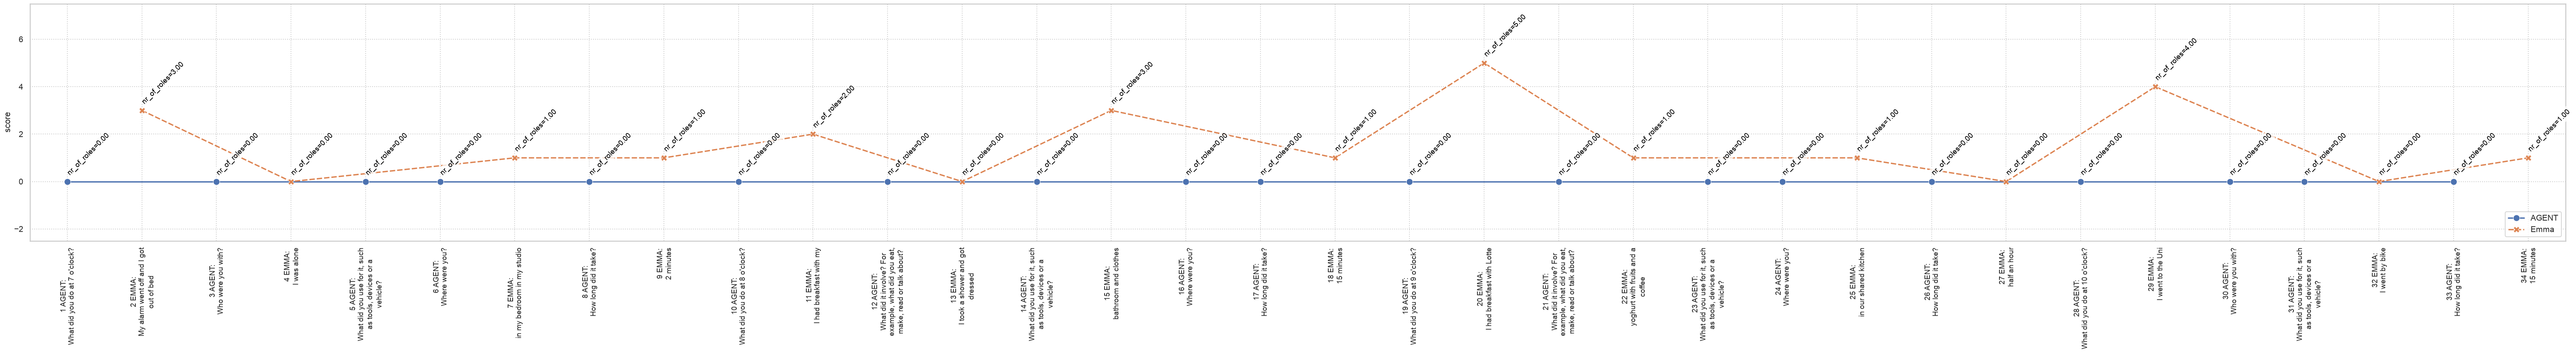

In [16]:
settings = plot.PlotSettings()
plot_file = plot.create_timeline_image_from_csv(turn_csv, "nr_of_roles", settings)

Nr of turns 34
Saved plot to /Users/piek/Desktop/Combot2026/ma-communicative-robots/data/collected_days/day_emma_20261021_1713_vs_day1_emma_student_turn_evaluation_nr_of_correct_roles_jaccard_plot.png



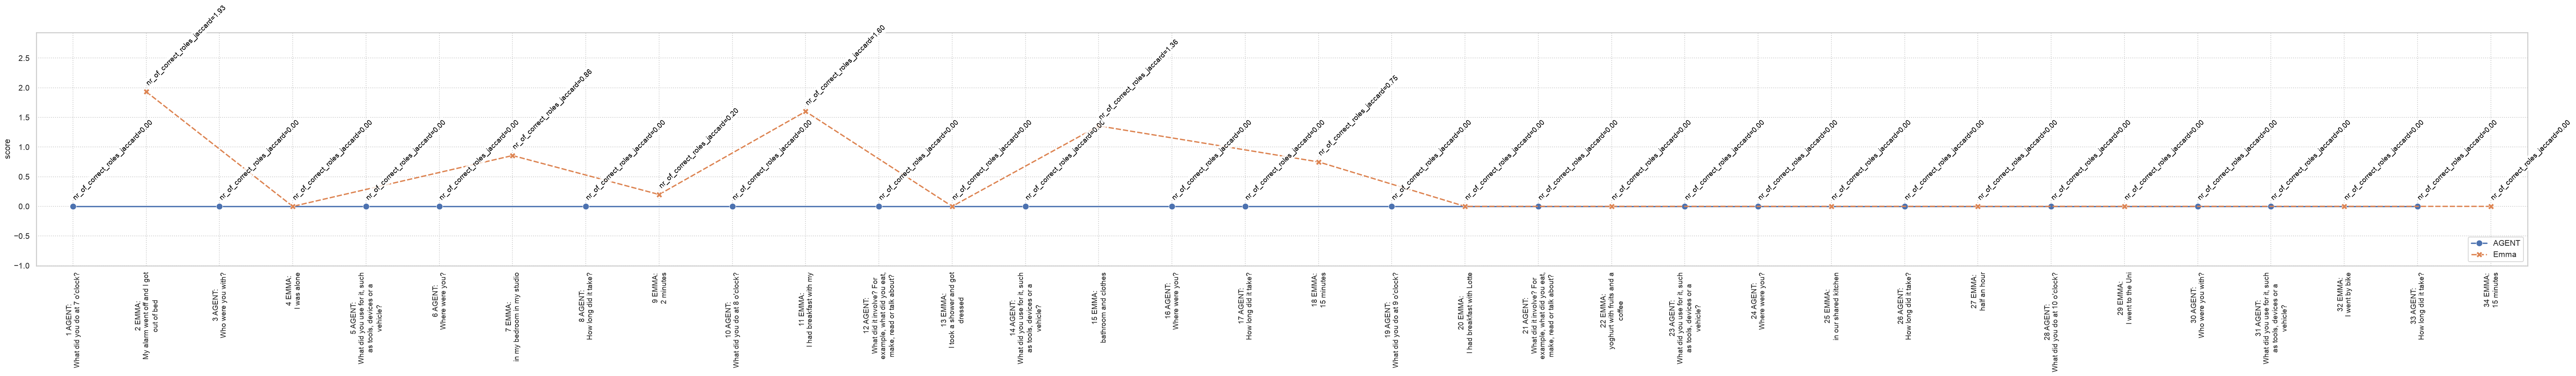

In [17]:
plot_file = plot.create_timeline_image_from_csv(turn_csv, "nr_of_correct_roles_jaccard", settings)